In [1]:
from langchain_naver import ChatClovaX
import os, requests
from typing import Annotated, List, TypedDict
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
from langchain_core.runnables import RunnableConfig

from prompt import *
from task1_tools import *
from task2_tools import *
from task3_tools import *
from utils import *

In [2]:
load_dotenv('/Users/yoon/MIRAE_ASSET_AI-Festival/.env')

clova = ChatClovaX(
    api_key=os.getenv('NCP_CLOVASTUDIO_API_KEY'),
    model="HCX-005",
    temperature=0.2,
    max_tokens=None,
    timeout=None,
    # max_retries,
    # repeat_penalt,
    # repetition_penalty,
    # stop,
    # seed,
    # top_k,
    # top_p,
)

In [3]:
class ChatbotState(TypedDict):
    question: Annotated[str, "Question"]  
    decision_task: Annotated[str, "Decision_task"]
    task_response: Annotated[str, "Task_Response"]
    answer: Annotated[str, "Final_Answer"]  
    messages: Annotated[List, add_messages] 

In [4]:
async def decision_task(state: ChatbotState):
    """
    LLM이 어떤 Task를 골랐는지 설명을 섞어 출력해도
    'Task1'·'Task2' … 형태로 정확히 추출해 state에 저장.
    """
    user_query = state["question"]

    prompt = TASK_ROUTER_PROMPT.format(question=user_query)
    messages = [("system", prompt)]

    llm_response = await clova.ainvoke(messages)
    raw_text = llm_response.content or ""

    normalized = re.sub(r"\s+", "", raw_text)

    m = re.search(r"task\s*([0-9]+)", normalized, re.IGNORECASE)

    decision = f"Task{m.group(1)}" if m else normalized

    return ChatbotState(decision_task = decision)

async def task1_tools(state: ChatbotState):
    user_query = state["question"]

    messages = [("system", TASK1_PROMPT),("human", user_query)]
    ai_msg = clova.invoke(messages)

    llm_question_analysis = parse_llm_json(ai_msg.content)

    result = asnwer_task1(llm_question_analysis)
    
    return ChatbotState(task_response=result)

async def task2_tools(state: ChatbotState):
    user_query = state["question"]

    messages = [("system", TASK2_PROMPT),("human", user_query)]
    ai_msg = clova.invoke(messages)

    llm_question_analysis = parse_llm_json(ai_msg.content)

    result = answer_task2(llm_question_analysis)
    
    return ChatbotState(task_response=result)

async def task3_tools(state: ChatbotState):
    user_query = state["question"]

    messages = [("system", TASK3_PROMPT),("human", user_query)]
    ai_msg = clova.invoke(messages)

    llm_question_analysis = parse_llm_json(ai_msg.content)

    result = answer_task3(llm_question_analysis)
    
    return ChatbotState(task_response=result)

async def task4_tools(state: ChatbotState):
    user_query = state["question"]

    data = {
    "model": "HCX-005",
    "messages": [
        {"role":"user","content": user_query}
    ],
    "tools" : [{"type": "function", "function": s} for s in task1_functions],
    "tool_choice": "auto"
    }

    response = requests.post(url, headers=headers, json=data)
    result = response.json()

    return ChatbotState(tools=result)

async def agent_answer(state: ChatbotState):
    user_query = state["question"]
    task_response = state['task_response']

    prompt = FINAL_ANSWER_PROMPT.format(question = user_query,
                                        task_result = task_response)
    messages = [("system", prompt)]
    llm_resp = await clova.ainvoke(messages)
    answer  = llm_resp.content.strip()

    return ChatbotState(answer=answer,
                        messages=[("user", user_query ), ("assistant", answer)])

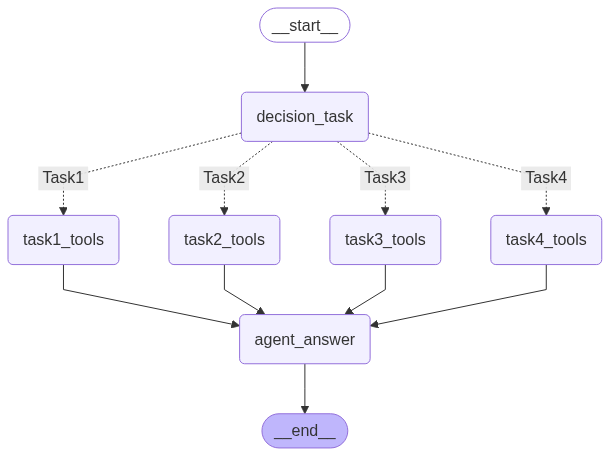

In [5]:
def route_tools(state: ChatbotState):
    return state["decision_task"]

builder = StateGraph(ChatbotState)

builder.add_node("decision_task", decision_task)
builder.add_node("task1_tools", task1_tools)
builder.add_node("task2_tools", task2_tools)
builder.add_node("task3_tools", task3_tools)
builder.add_node("task4_tools", task4_tools)
builder.add_node("agent_answer", agent_answer)

builder.add_edge(START, "decision_task")
builder.add_conditional_edges(
    "decision_task",
    route_tools,
    {"Task1": "task1_tools",
    "Task2": "task2_tools",
    "Task3": "task3_tools",
    "Task4": "task4_tools",}
    )
builder.add_edge("task1_tools", "agent_answer")
builder.add_edge("task2_tools", "agent_answer")
builder.add_edge("task3_tools", "agent_answer")
builder.add_edge("task4_tools", "agent_answer")
builder.add_edge("agent_answer", END)

builder.compile()

In [7]:
config = RunnableConfig(configurable={"thread_id": 1})

question = "2024-12-19에 등락률이 -10% 이하인 종목을 모두 보여줘"

graph = builder.compile()

initial_state = {
    "question": question,
    "decision_task":"",
    "tools": [],
    "tools_response" : [],
    "task2_response " : {},
    "answer": "",
    "messages": [],
} 

events = []
async for event in graph.astream(initial_state,config=config):
    print(event)
    events.append(event)

{'decision_task': {'decision_task': 'Task2'}}
Processing batch 1/14 (200 tickers)



2 Failed downloads:
['064400.KS', '499790.KS']: YFPricesMissingError('possibly delisted; no price data found  (1d 2024-12-14 00:00:00 -> 2024-12-20 00:00:00) (Yahoo error = "Data doesn\'t exist for startDate = 1734102000, endDate = 1734620400")')


✓ Batch 1 completed
Processing batch 2/14 (200 tickers)



1 Failed download:
['483650.KS']: YFPricesMissingError('possibly delisted; no price data found  (1d 2024-12-14 00:00:00 -> 2024-12-20 00:00:00) (Yahoo error = "Data doesn\'t exist for startDate = 1734102000, endDate = 1734620400")')


✓ Batch 2 completed
Processing batch 3/14 (200 tickers)



2 Failed downloads:
['031210.KS', '480370.KS']: YFPricesMissingError('possibly delisted; no price data found  (1d 2024-12-14 00:00:00 -> 2024-12-20 00:00:00) (Yahoo error = "Data doesn\'t exist for startDate = 1734102000, endDate = 1734620400")')


... (17 outputs left out)


6 Failed downloads:
['200230.KQ']: YFPricesMissingError('possibly delisted; no price data found  (1d 2024-12-14 00:00:00 -> 2024-12-20 00:00:00)')
['125020.KQ', '475430.KQ', '484810.KQ', '487720.KQ', '387570.KQ']: YFPricesMissingError('possibly delisted; no price data found  (1d 2024-12-14 00:00:00 -> 2024-12-20 00:00:00) (Yahoo error = "Data doesn\'t exist for startDate = 1734102000, endDate = 1734620400")')


✓ Batch 13 completed
Processing batch 14/14 (157 tickers)



3 Failed downloads:
['098070.KQ', '452450.KQ', '498390.KQ']: YFPricesMissingError('possibly delisted; no price data found  (1d 2024-12-14 00:00:00 -> 2024-12-20 00:00:00) (Yahoo error = "Data doesn\'t exist for startDate = 1734102000, endDate = 1734620400")')


✓ Batch 14 completed
Combining data for 2696 tickers...
Final data shape: (4, 16176)
Columns: ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
{'task2_tools': {'task_response': {'002630.KS': '오리엔트바이오', '008600.KS': '윌비스', '015020.KS': '이스타코', '013360.KS': '일성건설', '137940.KQ': '넥스트아이', '025950.KQ': '동신건설', '078160.KQ': '메디포스트', '288330.KQ': '브릿지바이오테라퓨틱스', '009620.KQ': '삼보산업', '308430.KQ': '셀비온', '394800.KQ': '쓰리빌리언', '065500.KQ': '오리엔트정공', '166480.KQ': '코아스템켐온', '121850.KQ': '코이즈'}}}
{'agent_answer': {'answer': '2024년 12월 19일에 등락률이 -10% 이하인 종목은 다음과 같습니다:\n\n1. 오리엔트바이오 (002630.KS)\n2. 윌비스 (008600.KS)\n3. 이스타코 (015020.KS)\n4. 일성건설 (013360.KS)\n5. 넥스트아이 (137940.KQ)\n6. 동신건설 (025950.KQ)\n7. 메디포스트 (078160.KQ)\n8. 브릿지바이오테라퓨틱스 (288330.KQ)\n9. 삼보산업 (009620.KQ)\n10. 셀비온 (308430.KQ)\n11. 쓰리빌리언 (394800.KQ)\n12. 오리엔트정공 (065500.KQ)\n13. 코아스템켐온 (166480.KQ)\n14. 코이즈 (121850.KQ)\n\n이 목록에는 다양한 산업 분야의 기업들이 포함되어 있으며, 주가가 큰 폭으로 하락한 이유를 개별적으로 분석해 볼 필요가 있습니다. 더 궁금한 점이나 추가 정보가 필요하시면 언제든지 말씀해 주세요!', 'me